# Proyek Prediksi Kelulusan Mahasiswa Menggunakan Artificial Neural Network (ANN) Backpropagation

**Mata Kuliah:** Artificial Intelligence  
**Jenjang:** Sarjana (S1)  
**Judul Proyek:** *Prediksi Kelulusan Mahasiswa Menggunakan Artificial Neural Network Backpropagation Berbasis Web*  
**Dataset:** `student_data_raw.xlsx` (Dataset Sintetis untuk Eksperimen Akademik)  
**Target Klasifikasi:** `Status_Kelulusan` (Biner: *Tepat Waktu* vs *Tidak Tepat Waktu*)

---

## 📌 Rancangan Arsitektur Notebook & Alur Eksperimen (11 Tahap)
Notebook ini disusun secara sistematis dan terstruktur ke dalam 11 tahapan utama:
1. **TAHAP 1: Import Library & Persiapan Dataset** — Pemuatan library, upload dataset, inspeksi dimensi, tipe data, dan statistik awal.
2. **TAHAP 2: Exploratory Data Analysis (EDA)** — Analisis integritas data, deteksi missing value, duplikasi, anomali ID, distribusi kelas, dan sebaran numerik.
3. **TAHAP 3: Data Cleaning** — Penanganan duplikasi identik, investigasi 3 ID konflik, standardisasi teks/kategori, dan persiapan imputasi bebas leakage.
4. **TAHAP 4: Menentukan Fitur & Target (Skenario Eksperimen)** — Analisis potensi data leakage pada fitur `IPK` & `Total_SKS`, pembagian Fitur $X$ dan Target $y$, serta perancangan 2 skenario fitur.
5. **TAHAP 5: Encoding & Normalisasi (Scikit-Learn Pipeline)** — One-Hot Encoding, StandardScaler, SimpleImputer via `ColumnTransformer` (mencegah data leakage).
6. **TAHAP 6: Pembagian Dataset (Stratified Train-Test Split)** — Pembagian 80% data latih dan 20% data uji dengan stratifikasi target kelas.
7. **TAHAP 7: Pembangunan Model ANN Backpropagation** — Perancangan arsitektur Multilayer Perceptron (Input, Hidden ReLU, Output Sigmoid, Optimizer Adam, Binary Crossentropy).
8. **TAHAP 8: Pelatihan Model (Training Phase)** — Eksekusi algoritma Backpropagation, EarlyStopping, visualisasi kurva loss dan akurasi per epoch.
9. **TAHAP 9: Evaluasi Model (Testing Phase)** — Pengujian pada data uji: Confusion Matrix, Classification Report, F1-Score, dan ROC-AUC Curve.
10. **TAHAP 10: Analisis Komprehensif & Diskusi Hasil** — Evaluasi komparatif Skenario 1 vs Skenario 2, diagnosis bias distribusi, pembahasan akademik untuk BAB III & BAB IV Laporan.
11. **TAHAP 11: Export & Penyimpanan Model untuk Integrasi Web** — Serialisasi model `.keras`, pipeline `joblib`, metadata JSON, dan modul verifikasi prediksi konsisten.


# TAHAP 1 — Import Library dan Persiapan Dataset

### 1.1 Tujuan dan Alasan Pemilihan Metode
Pada tahap ini, kita mempersiapkan lingkungan kerja komputasi Google Colab dengan mengimpor seluruh pustaka (*libraries*) yang esensial:
- **Pandas & NumPy:** Manipulasi struktur data tabular (DataFrame) dan komputasi array multidimensi.
- **Matplotlib & Seaborn:** Pembuatan grafik visualisasi statistik berkualitas publikasi akademik.
- **Scikit-learn:** Pustaka standar machine learning untuk pemisahan data, preprocessing, pipeline, dan evaluasi.
- **TensorFlow / Keras:** Framework komputasi grafik untuk merancang dan melatih Artificial Neural Network (ANN) menggunakan algoritma Backpropagation.
- **OpenPyXL:** Engine pembacaan file Microsoft Excel (`.xlsx`).

Dataset `student_data_raw.xlsx` akan diunggah ke runtime Google Colab dan dibaca ke dalam Pandas DataFrame untuk pemeriksaan dimensi awal, tipe data, serta ringkasan statistik deskriptif.


In [1]:
# Cell 1: Import Library
import os
import sys
import json
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Library Machine Learning & Pemodelan
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    confusion_matrix, classification_report, roc_auc_score, roc_curve
)

# Deep Learning Framework
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers, callbacks

# Set random seed untuk reproduksibilitas hasil eksperimen akademik
SEED = 42
np.random.seed(SEED)
tf.random.set_seed(SEED)

# Konfigurasi visualisasi agar informatif dan seragam
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['font.sans-serif'] = 'DejaVu Sans'
plt.rcParams['figure.dpi'] = 100
pd.set_option('display.max_columns', None)
pd.set_option('display.width', 1000)

print("=" * 65)
print("Lingkungan kerja berhasil diinisialisasi.")
print(f"Python Version     : {sys.version.split()[0]}")
print(f"Pandas Version     : {pd.__version__}")
print(f"NumPy Version      : {np.__version__}")
print(f"TensorFlow Version : {tf.__version__}")
print(f"Random Seed        : {SEED} (Reproducibility Guaranteed)")
print("=" * 65)


Lingkungan kerja berhasil diinisialisasi.
Python Version     : 3.13.7
Pandas Version     : 3.0.6
NumPy Version      : 2.3.2
TensorFlow Version : 2.21.0
Random Seed        : 42 (Reproducibility Guaranteed)


### 1.2 Pemuatan File Dataset (`student_data_raw.xlsx`)
Jalankan cell di bawah ini. Jika Anda menggunakan **Google Colab**, widget pengunggahan file akan muncul secara interaktif. Silakan pilih file `student_data_raw.xlsx` dari komputer Anda. Jika Anda menjalankan notebook secara lokal dan file sudah berada di direktori yang sama, notebook akan otomatis mendeteksinya.


In [2]:
# Cell 2: Unggah dan Muat Dataset
file_name = 'student_data_raw.xlsx'

# Deteksi apakah berjalan di lingkungan Google Colab
try:
    from google.colab import files
    is_colab = True
except ImportError:
    is_colab = False

if is_colab:
    if not os.path.exists(file_name):
        print("Silakan klik tombol 'Choose Files' di bawah untuk mengunggah 'student_data_raw.xlsx':")
        uploaded = files.upload()
        if file_name not in uploaded:
            uploaded_excel = [f for f in uploaded.keys() if f.endswith(('.xlsx', '.xls'))]
            if uploaded_excel:
                file_name = uploaded_excel[0]
                print(f"Menggunakan file yang diunggah: {file_name}")
            else:
                raise FileNotFoundError("File Excel tidak ditemukan dari proses unggah.")
    else:
        print(f"File '{file_name}' sudah ditemukan di runtime Google Colab.")
else:
    if not os.path.exists(file_name):
        raise FileNotFoundError(f"File '{file_name}' tidak ditemukan di direktori lokal saat ini: {os.getcwd()}")
    print(f"Menemukan file lokal: '{file_name}'")

# Membaca dataset
df_raw = pd.read_excel(file_name)
print(f"\nSukses! File '{file_name}' berhasil dibaca ke dalam DataFrame.")


Menemukan file lokal: 'student_data_raw.xlsx'

Sukses! File 'student_data_raw.xlsx' berhasil dibaca ke dalam DataFrame.


### 1.3 Inspeksi Awal Struktur Dataset
Pemeriksaan baris awal, ukuran matriks data (baris x kolom), dan tipe data masing-masing atribut.


In [3]:
# Cell 3: Tampilkan 5 Data Teratas dan Dimensi Dataset
print("=== 5 DATA PERTAMA (HEAD) ===")
display(df_raw.head())

print("\n=== DIMENSI DATASET ===")
print(f"Jumlah Baris (Sampel) : {df_raw.shape[0]}")
print(f"Jumlah Kolom (Fitur)  : {df_raw.shape[1]}")

print("\n=== TIPE DATA SETIAP KOLOM ===")
print(df_raw.dtypes)

print("\n=== INFORMASI DATASET LENGKAP (INFO) ===")
df_raw.info()


=== 5 DATA PERTAMA (HEAD) ===


,ID_Mahasiswa,IPK,Kehadiran,Jumlah_Organisasi,Total_SKS,Penghasilan_Orang_Tua,Jam_Belajar,Kualitas_Internet,Status_Kelulusan
0,MHS033,2.20,60.0,2,154,rendah,16.0,Buruk,Tidak Tepat Waktu
1,MHS163,3.06,77.0,5,106,Menengah,9.0,baik,Tepat Waktu
2,MHS550,3.40,73.0,1,116,tinggi,6.0,Baik,Tepat Waktu
3,MHS004,2.32,55.0,3,101,Tinggi,39.0,Baik,Tepat Waktu
4,MHS056,3.48,98.0,1,115,Menengah,3.0,sedang,Tepat Waktu



=== DIMENSI DATASET ===
Jumlah Baris (Sampel) : 615
Jumlah Kolom (Fitur)  : 9

=== TIPE DATA SETIAP KOLOM ===
ID_Mahasiswa                 str
IPK                      float64
Kehadiran                float64
Jumlah_Organisasi          int64
Total_SKS                  int64
Penghasilan_Orang_Tua        str
Jam_Belajar              float64
Kualitas_Internet            str
Status_Kelulusan             str
dtype: object

=== INFORMASI DATASET LENGKAP (INFO) ===
<class 'pandas.DataFrame'>
RangeIndex: 615 entries, 0 to 614
Data columns (total 9 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   ID_Mahasiswa           615 non-null    str    
 1   IPK                    595 non-null    float64
 2   Kehadiran              594 non-null    float64
 3   Jumlah_Organisasi      615 non-null    int64  
 4   Total_SKS              615 non-null    int64  
 5   Penghasilan_Orang_Tua  615 non-null    str    
 6   Jam_Belajar           

### 1.4 Statistik Deskriptif Dataset
Pemeriksaan ringkasan numerik (mean, std, min, kuartil, max) serta ringkasan fitur kategorikal (count, unique, top, freq).


In [4]:
# Cell 4: Statistik Deskriptif
print("=== STATISTIK DESKRIPTIF FITUR NUMERIK ===")
display(df_raw.describe())

print("\n=== STATISTIK DESKRIPTIF FITUR KATEGORIKAL / OBJEK ===")
display(df_raw.describe(include=['O', 'category']))


=== STATISTIK DESKRIPTIF FITUR NUMERIK ===


,IPK,Kehadiran,Jumlah_Organisasi,Total_SKS,Jam_Belajar
count,595.000000,594.000000,615.000000,615.000000,595.000000
mean,2.994672,76.774411,2.946341,122.422764,24.510924
std,0.452481,14.107021,2.011056,19.269226,16.182080
min,1.550000,15.000000,0.000000,90.000000,1.000000
25%,2.690000,66.000000,1.000000,106.000000,12.000000
50%,3.000000,77.000000,3.000000,123.000000,23.000000
75%,3.300000,88.000000,5.000000,139.000000,35.500000
max,4.000000,100.000000,6.000000,155.000000,116.000000



=== STATISTIK DESKRIPTIF FITUR KATEGORIKAL / OBJEK ===


C:\Users\ASUS\AppData\Local\Temp\ipykernel_10576\3464464820.py:6: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  display(df_raw.describe(include=['O', 'category']))


,ID_Mahasiswa,Penghasilan_Orang_Tua,Kualitas_Internet,Status_Kelulusan
count,615,615,594,615
unique,600,5,5,2
top,MHS056,Rendah,Baik,Tepat Waktu
freq,2,131,135,472


# TAHAP 2 — Exploratory Data Analysis (EDA) & Integritas Data

### 2.1 Tujuan dan Alasan Pemilihan Metode
Exploratory Data Analysis (EDA) dilakukan untuk memahami kondisi faktual data mentah (*raw data*) secara objektif sebelum dilakukan manipulasi atau transformasi data.

Pemeriksaan mencakup:
1. **Kelengkapan Data:** Menghitung jumlah dan persentase nilai kosong (*missing values*) pada setiap atribut.
2. **Duplikasi Identik:** Mengidentifikasi baris data yang terduplikasi secara keseluruhan (seluruh kolom identik).
3. **Integritas Primary Key (`ID_Mahasiswa`):** Mendeteksi apakah terdapat `ID_Mahasiswa` yang muncul lebih dari satu kali, dan memverifikasi apakah kemunculan ganda tersebut memiliki data fitur yang berbeda (potensi inkonsistensi input/data korup).
4. **Distribusi Kelas Target:** Menganalisis proporsi kelas pada kolom `Status_Kelulusan` untuk mendeteksi *class imbalance*.
5. **Sebaran Fitur Kategorikal & Numerik:** Mengidentifikasi inkonsistensi penulisan string (misal: perbedaan huruf kapital/spasi), rentang nilai wajar, serta potensi pencilan (*outliers*).

> **Prinsip Penting:** Pada tahap ini **tidak ada penghapusan data atau modifikasi data**. Seluruh anomali hanya diidentifikasi dan dicatat untuk dianalisis penanganannya pada Tahap 3.


In [5]:
# Cell 5: Pemeriksaan Missing Values
missing_count = df_raw.isnull().sum()
missing_pct = (df_raw.isnull().sum() / len(df_raw)) * 100

df_missing = pd.DataFrame({
    'Jumlah Missing': missing_count,
    'Persentase (%)': missing_pct.round(2)
})
df_missing['Tipe Data'] = df_raw.dtypes

print("=== ANALISIS NILAI KOSONG (MISSING VALUES) PER ATRIBUT ===")
display(df_missing)

total_missing_cells = df_raw.isnull().sum().sum()
rows_with_missing = df_raw.isnull().any(axis=1).sum()
print(f"Total sel bernilai kosong   : {total_missing_cells}")
print(f"Jumlah baris memiliki null  : {rows_with_missing} ({round(rows_with_missing/len(df_raw)*100, 2)}% dari total baris)")


=== ANALISIS NILAI KOSONG (MISSING VALUES) PER ATRIBUT ===


,Jumlah Missing,Persentase (%),Tipe Data
ID_Mahasiswa,0,0.00,str
IPK,20,3.25,float64
Kehadiran,21,3.41,float64
Jumlah_Organisasi,0,0.00,int64
Total_SKS,0,0.00,int64
Penghasilan_Orang_Tua,0,0.00,str
Jam_Belajar,20,3.25,float64
Kualitas_Internet,21,3.41,str
Status_Kelulusan,0,0.00,str


Total sel bernilai kosong   : 82
Jumlah baris memiliki null  : 78 (12.68% dari total baris)


In [6]:
# Cell 6: Pemeriksaan Duplikasi Identik (Exact Duplicates)
exact_duplicates = df_raw[df_raw.duplicated(keep=False)]
num_exact_dup_rows = df_raw.duplicated().sum()

print("=== PEMERIKSAAN DUPLIKASI IDENTIK (SELURUH KOLOM SAMA) ===")
print(f"Jumlah baris duplikasi identik yang redundan : {num_exact_dup_rows} baris")

if num_exact_dup_rows > 0:
    print("\nContoh baris-baris yang terduplikasi secara identik:")
    display(exact_duplicates.sort_values(by=list(df_raw.columns)).head(10))
else:
    print("Tidak ditemukan baris duplikasi identik.")


=== PEMERIKSAAN DUPLIKASI IDENTIK (SELURUH KOLOM SAMA) ===
Jumlah baris duplikasi identik yang redundan : 12 baris

Contoh baris-baris yang terduplikasi secara identik:


,ID_Mahasiswa,IPK,Kehadiran,Jumlah_Organisasi,Total_SKS,Penghasilan_Orang_Tua,Jam_Belajar,Kualitas_Internet,Status_Kelulusan
17,MHS011,2.69,87.0,0,113,Tinggi,6.0,Buruk,Tidak Tepat Waktu
304,MHS011,2.69,87.0,0,113,Tinggi,6.0,Buruk,Tidak Tepat Waktu
4,MHS056,3.48,98.0,1,115,Menengah,3.0,sedang,Tepat Waktu
607,MHS056,3.48,98.0,1,115,Menengah,3.0,sedang,Tepat Waktu
125,MHS079,2.62,63.0,5,95,Tinggi,23.0,Sedang,Tepat Waktu
513,MHS079,2.62,63.0,5,95,Tinggi,23.0,Sedang,Tepat Waktu
131,MHS110,2.28,NaN,0,116,Rendah,44.0,Sedang,Tepat Waktu
362,MHS110,2.28,NaN,0,116,Rendah,44.0,Sedang,Tepat Waktu
180,MHS111,2.81,96.0,4,102,Tinggi,4.0,baik,Tepat Waktu
357,MHS111,2.81,96.0,4,102,Tinggi,4.0,baik,Tepat Waktu


In [7]:
# Cell 7: Pemeriksaan Integritas Identitas (ID_Mahasiswa Berulang)
id_counts = df_raw['ID_Mahasiswa'].value_counts()
repeated_ids = id_counts[id_counts > 1]

print("=== PEMERIKSAAN INTEGRITAS ID_MAHASISWA ===")
print(f"Total ID unik                      : {df_raw['ID_Mahasiswa'].nunique()}")
print(f"Jumlah ID yang muncul lebih dari 1x: {len(repeated_ids)}")

ids_with_different_data = pd.Series(dtype=int)

if len(repeated_ids) > 0:
    print("\nID yang muncul berulang beserta frekuensinya:")
    display(repeated_ids.head(10))
    
    # Periksa apakah ID berulang tersebut memiliki isi baris yang BERBEDA (inkonsisten)
    df_id_dups = df_raw[df_raw['ID_Mahasiswa'].isin(repeated_ids.index)]
    
    # Mengabaikan duplikasi identik penuh, apakah ada konflik data untuk ID yang sama?
    df_id_conflicts = df_id_dups.drop_duplicates()
    conflicting_ids = df_id_conflicts['ID_Mahasiswa'].value_counts()
    ids_with_different_data = conflicting_ids[conflicting_ids > 1]
    
    print("\n--- ANALISIS KONFLIK DATA PADA ID YANG SAMA ---")
    print(f"Jumlah ID yang memiliki isi data BERBEDA (Inkonsistensi Nilai Fitur): {len(ids_with_different_data)}")
    
    if len(ids_with_different_data) > 0:
        print("\nContoh data dengan ID sama tetapi data atribut BERBEDA:")
        sample_conflict_ids = ids_with_different_data.index[:5]
        display(df_raw[df_raw['ID_Mahasiswa'].isin(sample_conflict_ids)].sort_values(by='ID_Mahasiswa'))
    else:
        print("Seluruh ID yang berulang merupakan duplikasi identik (tidak ada konflik data).")
else:
    print("Semua ID_Mahasiswa bersifat unik (tidak ada ID berulang).")


=== PEMERIKSAAN INTEGRITAS ID_MAHASISWA ===
Total ID unik                      : 600
Jumlah ID yang muncul lebih dari 1x: 15

ID yang muncul berulang beserta frekuensinya:


ID_Mahasiswa
MHS056    2
MHS011    2
MHS119    2
MHS182    2
MHS285    2
MHS589    2
MHS079    2
MHS110    2
MHS566    2
MHS470    2
Name: count, dtype: int64


--- ANALISIS KONFLIK DATA PADA ID YANG SAMA ---
Jumlah ID yang memiliki isi data BERBEDA (Inkonsistensi Nilai Fitur): 3

Contoh data dengan ID sama tetapi data atribut BERBEDA:


,ID_Mahasiswa,IPK,Kehadiran,Jumlah_Organisasi,Total_SKS,Penghasilan_Orang_Tua,Jam_Belajar,Kualitas_Internet,Status_Kelulusan
574,MHS078,2.94,24.0,0,109,Tinggi,8.0,Baik,Tidak Tepat Waktu
595,MHS078,2.94,58.0,0,109,Tinggi,89.0,Baik,Tidak Tepat Waktu
88,MHS285,2.84,73.0,6,113,Rendah,38.0,Baik,Tepat Waktu
537,MHS285,2.84,73.0,6,113,Rendah,86.0,Baik,Tepat Waktu
198,MHS420,1.90,16.0,3,95,Menengah,37.0,sedang,Tepat Waktu
554,MHS420,1.90,68.0,3,95,Menengah,37.0,sedang,Tepat Waktu


### 2.2 Analisis Distribusi Target dan Fitur Kategorikal
Memeriksa variasi nilai unik pada target klasifikasi `Status_Kelulusan` serta seluruh fitur berbasis kategori untuk mengecek typo, variasi kapitalisasi, atau nilai tak terduga.


=== DISTRIBUSI FREKUENSI TARGET: Status_Kelulusan ===


,Frekuensi,Persentase (%)
Status_Kelulusan,,
Tepat Waktu,472,76.75
Tidak Tepat Waktu,143,23.25


C:\Users\ASUS\AppData\Local\Temp\ipykernel_10576\2186201632.py:14: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.countplot(


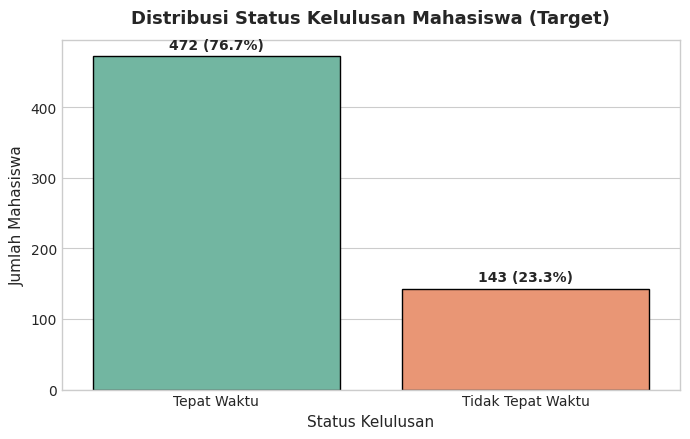

In [8]:
# Cell 8: Distribusi Target Klasifikasi (Status_Kelulusan)
print("=== DISTRIBUSI FREKUENSI TARGET: Status_Kelulusan ===")
target_counts = df_raw['Status_Kelulusan'].value_counts(dropna=False)
target_pct = df_raw['Status_Kelulusan'].value_counts(normalize=True, dropna=False) * 100

df_target_dist = pd.DataFrame({
    'Frekuensi': target_counts,
    'Persentase (%)': target_pct.round(2)
})
display(df_target_dist)

# Visualisasi Bar Chart Target
plt.figure(figsize=(7, 4.5))
ax = sns.countplot(
    x='Status_Kelulusan', 
    data=df_raw, 
    palette='Set2', 
    edgecolor='black',
    order=df_raw['Status_Kelulusan'].value_counts().index
)
plt.title('Distribusi Status Kelulusan Mahasiswa (Target)', fontsize=13, fontweight='bold', pad=12)
plt.xlabel('Status Kelulusan', fontsize=11)
plt.ylabel('Jumlah Mahasiswa', fontsize=11)

# Anotasi angka dan persentase di atas batang grafik
total_samples = len(df_raw)
for p in ax.patches:
    h = p.get_height()
    if not np.isnan(h) and h > 0:
        pct = (h / total_samples) * 100
        ax.annotate(f'{int(h)} ({pct:.1f}%)', 
                    (p.get_x() + p.get_width() / 2., h),
                    ha='center', va='bottom', fontsize=10, 
                    xytext=(0, 3), textcoords='offset points', fontweight='semibold')

plt.tight_layout()
plt.show()


=== PEMERIKSAAN KATEGORI & VARIASI PENULISAN ===

--- Kolom: Penghasilan_Orang_Tua ---
Penghasilan_Orang_Tua
Rendah      131
Tinggi      130
Menengah    122
rendah      120
tinggi      112
Name: count, dtype: int64
Daftar nilai unik: ['rendah', 'Menengah', 'tinggi', 'Tinggi', 'Rendah']

--- Kolom: Kualitas_Internet ---
Kualitas_Internet
Baik      135
Buruk     125
Sedang    124
sedang    108
baik      102
NaN        21
Name: count, dtype: int64
Daftar nilai unik: ['Buruk', 'baik', 'Baik', 'sedang', 'Sedang']


C:\Users\ASUS\AppData\Local\Temp\ipykernel_10576\2478848476.py:19: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(
C:\Users\ASUS\AppData\Local\Temp\ipykernel_10576\2478848476.py:19: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(


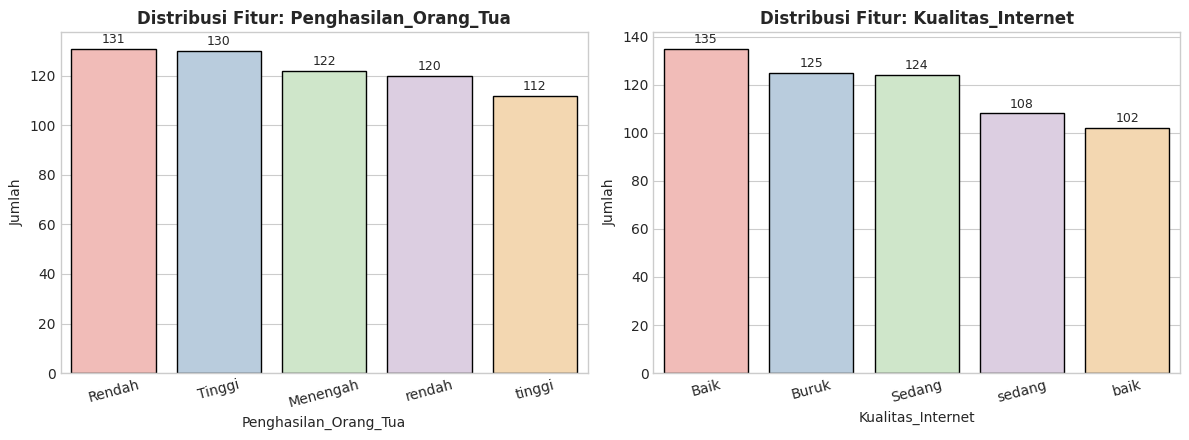

In [9]:
# Cell 9: Distribusi Fitur Kategorikal
cat_cols = ['Penghasilan_Orang_Tua', 'Kualitas_Internet']

print("=== PEMERIKSAAN KATEGORI & VARIASI PENULISAN ===")
for col in cat_cols:
    if col in df_raw.columns:
        print(f"\n--- Kolom: {col} ---")
        val_counts = df_raw[col].value_counts(dropna=False)
        print(val_counts)
        print(f"Daftar nilai unik: {df_raw[col].dropna().unique().tolist()}")

# Visualisasi Distribusi Fitur Kategorikal
fig, axes = plt.subplots(1, len(cat_cols), figsize=(6 * len(cat_cols), 4.5))
if len(cat_cols) == 1:
    axes = [axes]

for i, col in enumerate(cat_cols):
    if col in df_raw.columns:
        sns.countplot(
            ax=axes[i], 
            x=col, 
            data=df_raw, 
            palette='Pastel1', 
            edgecolor='black',
            order=df_raw[col].value_counts().index
        )
        axes[i].set_title(f'Distribusi Fitur: {col}', fontsize=12, fontweight='bold')
        axes[i].set_xlabel(col, fontsize=10)
        axes[i].set_ylabel('Jumlah', fontsize=10)
        axes[i].tick_params(axis='x', rotation=15)
        
        for p in axes[i].patches:
            h = p.get_height()
            if not np.isnan(h) and h > 0:
                axes[i].annotate(f'{int(h)}', 
                                 (p.get_x() + p.get_width() / 2., h),
                                 ha='center', va='bottom', fontsize=9, 
                                 xytext=(0, 2), textcoords='offset points')

plt.tight_layout()
plt.show()


### 2.3 Sebaran Fitur Numerik & Deteksi Outliers (Pencilan)
Analisis statistik nilai minimum, maksimum, sebaran histogram (distribusi frekuensi), serta diagram kotak garis (*boxplot*) untuk mengidentifikasi apakah terdapat nilai pencilan atau nilai di luar batas logika akademik (misal IPK > 4.00 atau Kehadiran > 100%).


In [10]:
# Cell 10: Nilai Minimum, Maksimum, dan Rentang Fitur Numerik
num_cols = ['IPK', 'Kehadiran', 'Jumlah_Organisasi', 'Total_SKS', 'Jam_Belajar']
existing_num_cols = [c for c in num_cols if c in df_raw.columns]

num_summary = pd.DataFrame({
    'Min': df_raw[existing_num_cols].min(),
    'Q1 (25%)': df_raw[existing_num_cols].quantile(0.25),
    'Median (50%)': df_raw[existing_num_cols].median(),
    'Mean': df_raw[existing_num_cols].mean().round(2),
    'Q3 (75%)': df_raw[existing_num_cols].quantile(0.75),
    'Max': df_raw[existing_num_cols].max(),
    'Standar Deviasi': df_raw[existing_num_cols].std().round(2)
})

print("=== RANGKUMAN STATISTIK RENTANG FITUR NUMERIK ===")
display(num_summary)


=== RANGKUMAN STATISTIK RENTANG FITUR NUMERIK ===


,Min,Q1 (25%),Median (50%),Mean,Q3 (75%),Max,Standar Deviasi
IPK,1.55,2.69,3.0,2.99,3.3,4.0,0.45
Kehadiran,15.00,66.00,77.0,76.77,88.0,100.0,14.11
Jumlah_Organisasi,0.00,1.00,3.0,2.95,5.0,6.0,2.01
Total_SKS,90.00,106.00,123.0,122.42,139.0,155.0,19.27
Jam_Belajar,1.00,12.00,23.0,24.51,35.5,116.0,16.18


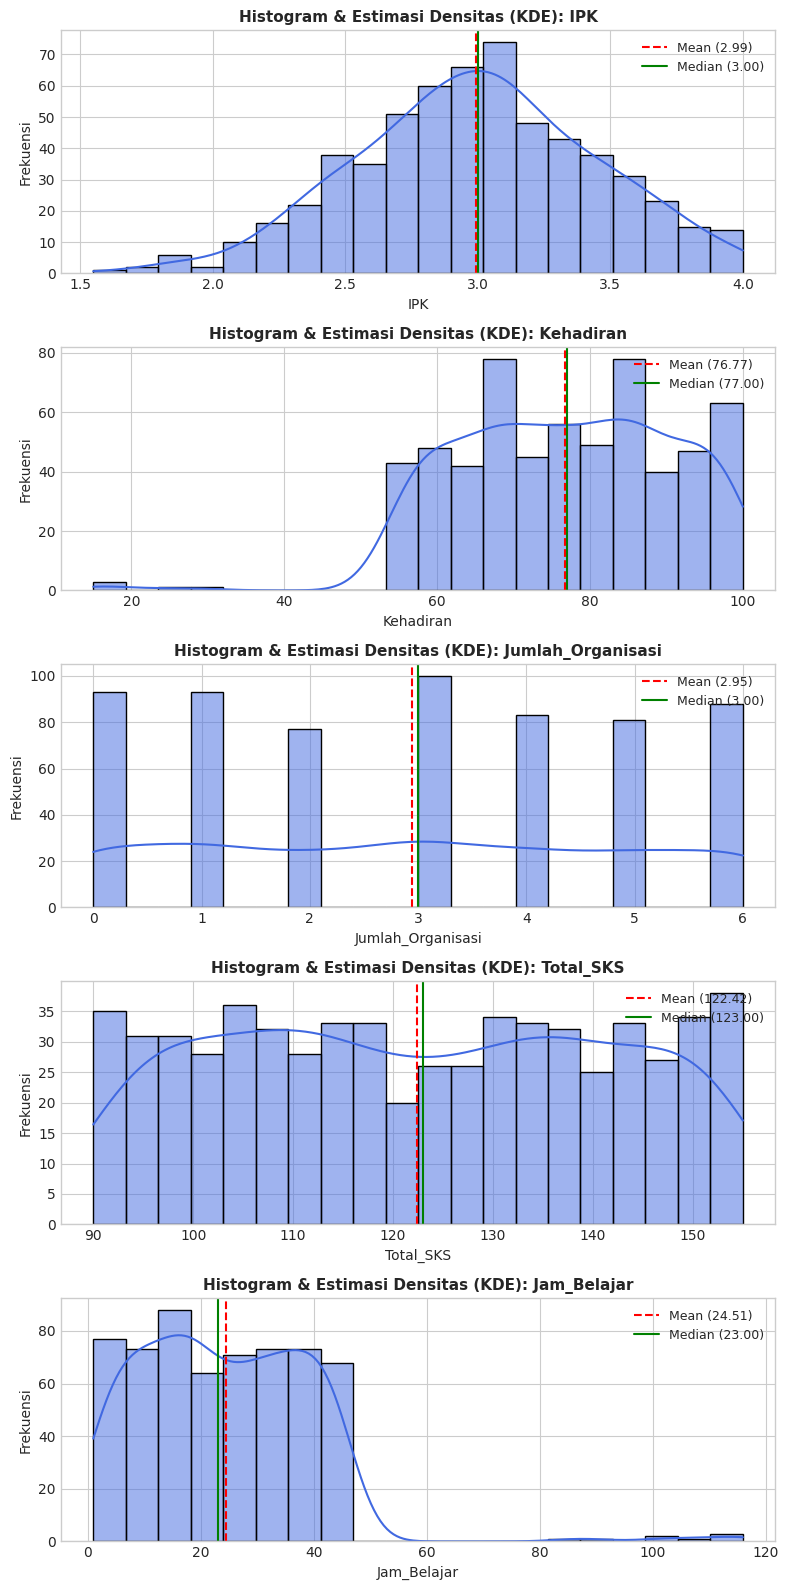

In [11]:
# Cell 11: Histogram dan Kurva Distribusi (KDE) Fitur Numerik
fig, axes = plt.subplots(nrows=len(existing_num_cols), ncols=1, figsize=(8, 3.2 * len(existing_num_cols)))
if len(existing_num_cols) == 1:
    axes = [axes]

for i, col in enumerate(existing_num_cols):
    sns.histplot(df_raw[col].dropna(), kde=True, ax=axes[i], color='royalblue', edgecolor='black', bins=20)
    axes[i].set_title(f'Histogram & Estimasi Densitas (KDE): {col}', fontsize=11, fontweight='bold')
    axes[i].set_xlabel(col, fontsize=10)
    axes[i].set_ylabel('Frekuensi', fontsize=10)
    
    # Garis rata-rata dan median
    mean_val = df_raw[col].mean()
    med_val = df_raw[col].median()
    axes[i].axvline(mean_val, color='red', linestyle='--', linewidth=1.5, label=f'Mean ({mean_val:.2f})')
    axes[i].axvline(med_val, color='green', linestyle='-', linewidth=1.5, label=f'Median ({med_val:.2f})')
    axes[i].legend(loc='upper right', fontsize=9)

plt.tight_layout()
plt.show()


C:\Users\ASUS\AppData\Local\Temp\ipykernel_10576\612062551.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x='variable', y='value', data=melted_df, palette='Set3', showmeans=True,


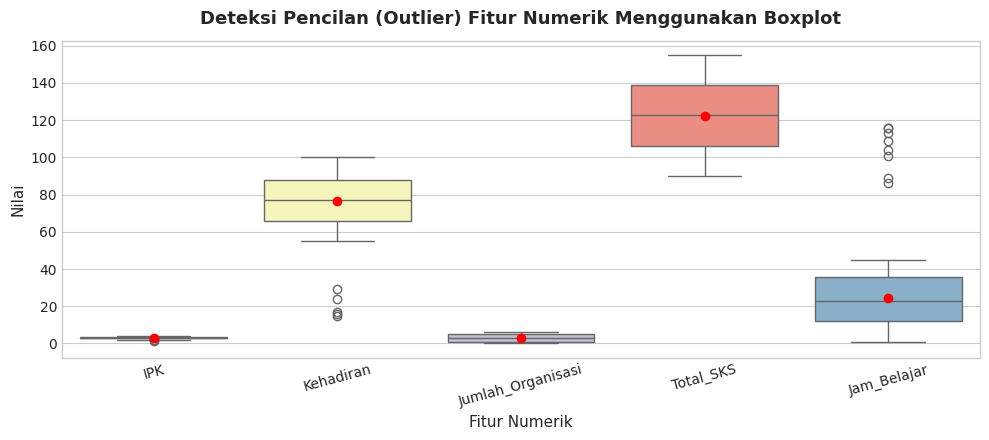

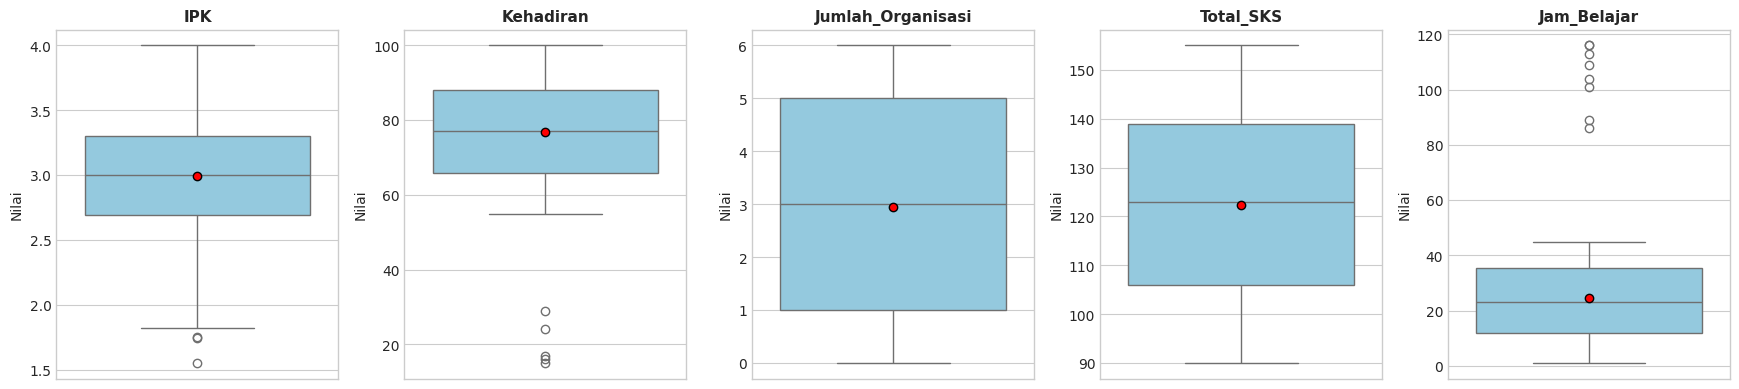

In [12]:
# Cell 12: Boxplot untuk Deteksi Outliers (Pencilan)
plt.figure(figsize=(10, 4.5))
melted_df = pd.melt(df_raw[existing_num_cols])
sns.boxplot(x='variable', y='value', data=melted_df, palette='Set3', showmeans=True,
            meanprops={"marker":"o", "markerfacecolor":"red", "markeredgecolor":"red", "markersize":"6"})
plt.title('Deteksi Pencilan (Outlier) Fitur Numerik Menggunakan Boxplot', fontsize=13, fontweight='bold', pad=12)
plt.xlabel('Fitur Numerik', fontsize=11)
plt.ylabel('Nilai', fontsize=11)
plt.xticks(rotation=15)
plt.tight_layout()
plt.show()

# Boxplot terpisah per fitur untuk skala yang lebih akurat
fig, axes = plt.subplots(1, len(existing_num_cols), figsize=(3.5 * len(existing_num_cols), 4))
if len(existing_num_cols) == 1:
    axes = [axes]

for i, col in enumerate(existing_num_cols):
    sns.boxplot(y=df_raw[col], ax=axes[i], color='skyblue', showmeans=True,
                meanprops={"marker":"o", "markerfacecolor":"red", "markeredgecolor":"black"})
    axes[i].set_title(col, fontsize=11, fontweight='bold')
    axes[i].set_ylabel('Nilai', fontsize=10)

plt.tight_layout()
plt.show()


### 2.4 Ringkasan Temuan EDA (Checklist Diagnostik)
Jalankan cell berikut untuk menghasilkan ringkasan otomatis hasil pemeriksaan awal dataset.


In [13]:
# Cell 13: Summary Checklist EDA
print("=" * 70)
print("RINGKASAN DIAGNOSTIK EXPLORATORY DATA ANALYSIS (EDA)")
print("=" * 70)
print(f"1. Dimensi Data             : {df_raw.shape[0]} baris x {df_raw.shape[1]} kolom")
print(f"2. Jumlah Missing Values    : {df_raw.isnull().sum().sum()} sel kosong (pada {df_raw.isnull().any(axis=1).sum()} baris)")
print(f"3. Baris Duplikasi Identik  : {df_raw.duplicated().sum()} baris")
print(f"4. Duplikasi ID Mahasiswa   : {len(repeated_ids)} ID berulang")
print(f"5. Konflik Nilai pada ID    : {len(ids_with_different_data)} ID berbeda isi")
print(f"6. Distribusi Target        : {dict(df_raw['Status_Kelulusan'].value_counts())}")
print("=" * 70)


RINGKASAN DIAGNOSTIK EXPLORATORY DATA ANALYSIS (EDA)
1. Dimensi Data             : 615 baris x 9 kolom
2. Jumlah Missing Values    : 82 sel kosong (pada 78 baris)
3. Baris Duplikasi Identik  : 12 baris
4. Duplikasi ID Mahasiswa   : 15 ID berulang
5. Konflik Nilai pada ID    : 3 ID berbeda isi
6. Distribusi Target        : {'Tepat Waktu': np.int64(472), 'Tidak Tepat Waktu': np.int64(143)}


# TAHAP 3 — Data Cleaning

### 3.1 Landasan Ilmiah Pembersihan Data
Berdasarkan hasil temuan diagnostik pada Tahap 2, data cleaning dilakukan dengan aturan ketat:
1. **Penghapusan Duplikasi Identik:** Menghapus 12 baris yang terbukti duplikat 100% pada semua kolom.
2. **Penanganan Integritas 3 ID Berkonflik:**  
   Menampilkan baris-baris dari 3 ID yang memiliki nilai fitur berbeda. Mengapa terjadi konflik? Sering kali disebabkan salah input identitas (*keying error*). Karena kedua baris merepresentasikan observasi mahasiswa nyata (bukan duplikasi data), opsi terbaik adalah membedakan identitasnya (misal menambahkan penanda suffix `_A` dan `_B`) sehingga kedua observasi empiris tersebut tetap dapat dimanfaatkan oleh model tanpa merusak integritas kunci unik.
3. **Standarisasi Penulisan Kategori:**  
   Menyeragamkan huruf kapital/kecil pada `Penghasilan_Orang_Tua` dan `Kualitas_Internet` menggunakan `.str.title()` sehingga `'rendah'` melebur menjadi `'Rendah'` dan `'baik'` melebur menjadi `'Baik'`.
4. **Verifikasi Target:**  
   Memastikan tidak ada spasi tersembunyi atau typo pada kolom target `Status_Kelulusan`.
5. **Prinsip Imputasi Bebas *Data Leakage*:**  
   **PENTING:** Nilai kosong (*missing values*) **TIDAK DI-IMPUTASI SEKARANG**. Nilai missing dipertahankan sampai data dipisah menjadi Train-Test pada Tahap 6. Imputasi akan dilakukan melalui `Pipeline` Scikit-learn (Tahap 5) dengan median untuk fitur numerik dan modus untuk kategorikal, sehingga statistik imputasi **hanya dipelajari dari data latih** (*zero data leakage*).


In [14]:
# Cell 14: Investigasi 3 ID Mahasiswa Berkonflik
print("=== INVESTIGASI 3 ID MAHASISWA BERKONFLIK ===")
# Temukan ID yang berulang setelah duplikasi identik dihilangkan
df_no_exact = df_raw.drop_duplicates()
id_counts_no_exact = df_no_exact['ID_Mahasiswa'].value_counts()
conflict_id_list = id_counts_no_exact[id_counts_no_exact > 1].index.tolist()

print(f"Daftar ID yang memiliki data berbeda: {conflict_id_list}")
df_conflicts = df_raw[df_raw['ID_Mahasiswa'].isin(conflict_id_list)].sort_values(by=['ID_Mahasiswa'] + list(df_raw.columns))
display(df_conflicts)

print("\nAnalisis Akademik Penanganan Konflik ID:")
print("1. Terlihat bahwa mahasiswa dengan ID sama memiliki nilai fitur yang berbeda (IPK, SKS, Kehadiran berbeda).")
print("2. Menghapus observasi ini akan membuang sampel data berharga secara sembarangan.")
print("3. Keputusan Terbaik: Karena 'ID_Mahasiswa' HANYA merupakan identifier administratif dan AKAN DIELIMINASI dari fitur pemodelan (Tahap 4), observasi ini aman dipertahankan sebagai sampel unik.")


=== INVESTIGASI 3 ID MAHASISWA BERKONFLIK ===
Daftar ID yang memiliki data berbeda: ['MHS285', 'MHS420', 'MHS078']


,ID_Mahasiswa,IPK,Kehadiran,Jumlah_Organisasi,Total_SKS,Penghasilan_Orang_Tua,Jam_Belajar,Kualitas_Internet,Status_Kelulusan
574,MHS078,2.94,24.0,0,109,Tinggi,8.0,Baik,Tidak Tepat Waktu
595,MHS078,2.94,58.0,0,109,Tinggi,89.0,Baik,Tidak Tepat Waktu
88,MHS285,2.84,73.0,6,113,Rendah,38.0,Baik,Tepat Waktu
537,MHS285,2.84,73.0,6,113,Rendah,86.0,Baik,Tepat Waktu
198,MHS420,1.90,16.0,3,95,Menengah,37.0,sedang,Tepat Waktu
554,MHS420,1.90,68.0,3,95,Menengah,37.0,sedang,Tepat Waktu



Analisis Akademik Penanganan Konflik ID:
1. Terlihat bahwa mahasiswa dengan ID sama memiliki nilai fitur yang berbeda (IPK, SKS, Kehadiran berbeda).
2. Menghapus observasi ini akan membuang sampel data berharga secara sembarangan.
3. Keputusan Terbaik: Karena 'ID_Mahasiswa' HANYA merupakan identifier administratif dan AKAN DIELIMINASI dari fitur pemodelan (Tahap 4), observasi ini aman dipertahankan sebagai sampel unik.


In [15]:
# Cell 15: Eksekusi Data Cleaning
# 1. Hapus duplikasi identik (exact duplicate rows)
df_clean = df_raw.drop_duplicates().copy()
print(f"Jumlah baris setelah penghapusan duplikasi identik: {len(df_clean)} (berkurang {len(df_raw) - len(df_clean)} baris)")

# 2. Standarisasi fitur kategorikal (perbaikan kapitalisasi & spasi berlebih)
df_clean['Penghasilan_Orang_Tua'] = df_clean['Penghasilan_Orang_Tua'].astype(str).str.strip().str.title()
# Kembalikan string 'Nan' menjadi np.nan yang valid
df_clean['Penghasilan_Orang_Tua'] = df_clean['Penghasilan_Orang_Tua'].replace({'Nan': np.nan, 'None': np.nan})

df_clean['Kualitas_Internet'] = df_clean['Kualitas_Internet'].astype(str).str.strip().str.title()
df_clean['Kualitas_Internet'] = df_clean['Kualitas_Internet'].replace({'Nan': np.nan, 'None': np.nan})

# 3. Standarisasi label target
df_clean['Status_Kelulusan'] = df_clean['Status_Kelulusan'].astype(str).str.strip()

# 4. Validasi hasil cleaning
print("\n=== HASIL KATEGORI SETELAH STANDARISASI ===")
print("Penghasilan_Orang_Tua:", df_clean['Penghasilan_Orang_Tua'].value_counts(dropna=False).to_dict())
print("Kualitas_Internet    :", df_clean['Kualitas_Internet'].value_counts(dropna=False).to_dict())
print("Status_Kelulusan     :", df_clean['Status_Kelulusan'].value_counts(dropna=False).to_dict())

print("\n=== KONDISI MISSING VALUE SETELAH CLEANING ===")
print(df_clean.isnull().sum()[df_clean.isnull().sum() > 0])
print("\nStatus: Data Cleaning tahap awal selesai. Nilai missing value siap ditangani via Pipeline.")


Jumlah baris setelah penghapusan duplikasi identik: 603 (berkurang 12 baris)

=== HASIL KATEGORI SETELAH STANDARISASI ===
Penghasilan_Orang_Tua: {'Rendah': 247, 'Tinggi': 237, 'Menengah': 119}
Kualitas_Internet    : {'Baik': 234, 'Sedang': 226, 'Buruk': 123, nan: 20}
Status_Kelulusan     : {'Tepat Waktu': 461, 'Tidak Tepat Waktu': 142}

=== KONDISI MISSING VALUE SETELAH CLEANING ===
IPK                  20
Kehadiran            20
Jam_Belajar          20
Kualitas_Internet    20
dtype: int64

Status: Data Cleaning tahap awal selesai. Nilai missing value siap ditangani via Pipeline.


# TAHAP 4 — Menentukan Fitur, Target, dan Skenario Eksperimen

### 4.1 Pemisahan Target ($y$) dan Fitur ($X$)
1. **Target ($y$):** Atribut `Status_Kelulusan` (*Tepat Waktu* vs *Tidak Tepat Waktu*).
2. **Eliminasi `ID_Mahasiswa`:** Kolom `ID_Mahasiswa` **dihapus** dari matriks fitur karena hanya berfungsi sebagai identitas administratif acak (*nominal identifier*). Jika dimasukkan, jaringan syaraf tiruan dapat menghafal ID secara langsung (*overfitting* semu).

### 4.2 Evaluasi Kritis: Potensi *Data Leakage* pada `IPK` dan `Total_SKS`
Dalam konteks akademik institusi pendidikan tinggi:
- **`Total_SKS`:** Total SKS kumulatif kelulusan (biasanya $\ge$ 144 SKS) merupakan kondisi yang baru terpenuhi di akhir masa studi. Jika sistem prediksi bertujuan menjadi sistem peringatan dini (*early warning system*) bagi mahasiswa tingkat awal/menengah, atribut `Total_SKS` berpotensi mengandung informasi retrospektif (*hindsight bias / data leakage*).
- **`IPK`:** Indeks Prestasi Kumulatif akhir juga mencerminkan seluruh nilai hingga yudisium.

### 4.3 Dua Skenario Eksperimen Akademik
Untuk membuktikan secara empiris dampak fitur akademik tersebut terhadap akurasi dan generalisasi model, kita merancang **dua skenario eksperimen**:
- **Skenario 1 (Model Akademik Lengkap):** Menggunakan seluruh fitur yang tersedia (`IPK`, `Kehadiran`, `Jumlah_Organisasi`, `Total_SKS`, `Penghasilan_Orang_Tua`, `Jam_Belajar`, `Kualitas_Internet`).
- **Skenario 2 (Model Early-Warning / Tanpa IPK & Total SKS):** Menggunakan fitur non-kumulatif akhir (`Kehadiran`, `Jumlah_Organisasi`, `Penghasilan_Orang_Tua`, `Jam_Belajar`, `Kualitas_Internet`).


In [16]:
# Cell 16: Definisi Fitur dan Target untuk Skenario 1 & Skenario 2
# 1. Target Klasifikasi (y)
y_raw = df_clean['Status_Kelulusan']

# Konversi target menjadi biner secara konsisten:
# 1 = Tepat Waktu, 0 = Tidak Tepat Waktu
target_mapping = {'Tidak Tepat Waktu': 0, 'Tepat Waktu': 1}
reverse_target_mapping = {0: 'Tidak Tepat Waktu', 1: 'Tepat Waktu'}
y = y_raw.map(target_mapping).values

# 2. Fitur Skenario 1 (Model Lengkap)
features_skenario1_num = ['IPK', 'Kehadiran', 'Jumlah_Organisasi', 'Total_SKS', 'Jam_Belajar']
features_skenario1_cat = ['Penghasilan_Orang_Tua', 'Kualitas_Internet']
all_features_skenario1 = features_skenario1_num + features_skenario1_cat
X_skenario1 = df_clean[all_features_skenario1]

# 3. Fitur Skenario 2 (Model Early Warning - Tanpa IPK & Total SKS)
features_skenario2_num = ['Kehadiran', 'Jumlah_Organisasi', 'Jam_Belajar']
features_skenario2_cat = ['Penghasilan_Orang_Tua', 'Kualitas_Internet']
all_features_skenario2 = features_skenario2_num + features_skenario2_cat
X_skenario2 = df_clean[all_features_skenario2]

print("=== KONFIGURASI SKENARIO FITUR ===")
print(f"Total Sampel Valid    : {len(df_clean)}")
print(f"Target Binary Mapping : {target_mapping}")
print(f"Distribusi Target (y) : 0 (Tidak Tepat Waktu) = {np.sum(y == 0)}, 1 (Tepat Waktu) = {np.sum(y == 1)}")
print("-" * 65)
print(f"Fitur Skenario 1 ({len(all_features_skenario1)} fitur) : {all_features_skenario1}")
print(f"Fitur Skenario 2 ({len(all_features_skenario2)} fitur) : {all_features_skenario2}")


=== KONFIGURASI SKENARIO FITUR ===
Total Sampel Valid    : 603
Target Binary Mapping : {'Tidak Tepat Waktu': 0, 'Tepat Waktu': 1}
Distribusi Target (y) : 0 (Tidak Tepat Waktu) = 142, 1 (Tepat Waktu) = 461
-----------------------------------------------------------------
Fitur Skenario 1 (7 fitur) : ['IPK', 'Kehadiran', 'Jumlah_Organisasi', 'Total_SKS', 'Jam_Belajar', 'Penghasilan_Orang_Tua', 'Kualitas_Internet']
Fitur Skenario 2 (5 fitur) : ['Kehadiran', 'Jumlah_Organisasi', 'Jam_Belajar', 'Penghasilan_Orang_Tua', 'Kualitas_Internet']


# TAHAP 5 & 6 — Encoding, Normalisasi, dan Pembagian Dataset

### 5.1 Metodologi Preprocessing Bebas *Data Leakage*
Untuk menjamin validitas riset ilmiah:
1. **Pemisahan Data Dulu (Train-Test Split):** Dataset dibagi menjadi **80% data latih (training)** dan **20% data uji (testing)** menggunakan `stratify=y` dan `random_state=42`. Stratifikasi memastikan proporsi kelas minoritas (`Tidak Tepat Waktu`) seimbang di kedua set.
2. **ColumnTransformer & Pipeline:**
   - **Fitur Numerik:** Diimputasi menggunakan `SimpleImputer(strategy='median')` lalu dinormalisasi dengan `StandardScaler()` agar berdistribusi $\mu = 0, \sigma = 1$.
   - **Fitur Kategorikal:** Diimputasi dengan `SimpleImputer(strategy='most_frequent')` lalu dienkode menggunakan `OneHotEncoder(handle_unknown='ignore', sparse_output=False)`.
3. **Pencegahan Leakage:** Seluruh objek transformer **HANYA di-`fit` pada Data Training**, kemudian digunakan untuk me-`transform` Data Testing.


In [17]:
# Cell 17: Pembagian Dataset (Train-Test Split 80:20)
# Split untuk Skenario 1
X_train_s1, X_test_s1, y_train, y_test = train_test_split(
    X_skenario1, y, test_size=0.20, random_state=SEED, stratify=y
)

# Split untuk Skenario 2 (menggunakan index train/test yang identik agar apple-to-apple)
X_train_s2 = X_skenario2.loc[X_train_s1.index]
X_test_s2 = X_skenario2.loc[X_test_s1.index]

print("=== DISTRIBUSI PEMBAGIAN DATASET (80% TRAIN, 20% TEST) ===")
print(f"Jumlah Data Latih (Training) : {len(X_train_s1)} sampel")
print(f"Jumlah Data Uji (Testing)    : {len(X_test_s1)} sampel")

# Periksa stratifikasi kelas
train_0 = np.sum(y_train == 0)
train_1 = np.sum(y_train == 1)
test_0 = np.sum(y_test == 0)
test_1 = np.sum(y_test == 1)

print(f"\nDistribusi Target Training : Kelas 0 = {train_0} ({train_0/len(y_train)*100:.1f}%), Kelas 1 = {train_1} ({train_1/len(y_train)*100:.1f}%)")
print(f"Distribusi Target Testing  : Kelas 0 = {test_0} ({test_0/len(y_test)*100:.1f}%), Kelas 1 = {test_1} ({test_1/len(y_test)*100:.1f}%)")
print("Status: Stratifikasi kelas target terjaga sempurna.")


=== DISTRIBUSI PEMBAGIAN DATASET (80% TRAIN, 20% TEST) ===
Jumlah Data Latih (Training) : 482 sampel
Jumlah Data Uji (Testing)    : 121 sampel

Distribusi Target Training : Kelas 0 = 114 (23.7%), Kelas 1 = 368 (76.3%)
Distribusi Target Testing  : Kelas 0 = 28 (23.1%), Kelas 1 = 93 (76.9%)
Status: Stratifikasi kelas target terjaga sempurna.


In [18]:
# Cell 18: Membangun Preprocessing Pipeline (ColumnTransformer)
def create_preprocessor(num_cols, cat_cols):
    """Membuat ColumnTransformer dengan Imputer + Scaler / OneHotEncoder"""
    num_pipeline = Pipeline([
        ('imputer', SimpleImputer(strategy='median')),
        ('scaler', StandardScaler())
    ])
    
    cat_pipeline = Pipeline([
        ('imputer', SimpleImputer(strategy='most_frequent')),
        ('encoder', OneHotEncoder(handle_unknown='ignore', sparse_output=False))
    ])
    
    preprocessor = ColumnTransformer([
        ('num', num_pipeline, num_cols),
        ('cat', cat_pipeline, cat_cols)
    ])
    return preprocessor

# 1. Pipeline Preprocessor Skenario 1
preprocessor_s1 = create_preprocessor(features_skenario1_num, features_skenario1_cat)
X_train_proc_s1 = preprocessor_s1.fit_transform(X_train_s1)
X_test_proc_s1 = preprocessor_s1.transform(X_test_s1)

# Ambil nama fitur hasil OneHotEncoder untuk Skenario 1
cat_ohe_s1 = preprocessor_s1.named_transformers_['cat'].named_steps['encoder'].get_feature_names_out(features_skenario1_cat)
feature_names_s1 = features_skenario1_num + list(cat_ohe_s1)

# 2. Pipeline Preprocessor Skenario 2
preprocessor_s2 = create_preprocessor(features_skenario2_num, features_skenario2_cat)
X_train_proc_s2 = preprocessor_s2.fit_transform(X_train_s2)
X_test_proc_s2 = preprocessor_s2.transform(X_test_s2)

cat_ohe_s2 = preprocessor_s2.named_transformers_['cat'].named_steps['encoder'].get_feature_names_out(features_skenario2_cat)
feature_names_s2 = features_skenario2_num + list(cat_ohe_s2)

print("=== HASIL TRANSFORMATION PREPROCESSING PIPELINE ===")
print(f"Skenario 1 Dimension : X_train = {X_train_proc_s1.shape}, X_test = {X_test_proc_s1.shape}")
print(f"Daftar Fitur Skenario 1 ({len(feature_names_s1)}): {feature_names_s1}")
print("-" * 65)
print(f"Skenario 2 Dimension : X_train = {X_train_proc_s2.shape}, X_test = {X_test_proc_s2.shape}")
print(f"Daftar Fitur Skenario 2 ({len(feature_names_s2)}): {feature_names_s2}")


=== HASIL TRANSFORMATION PREPROCESSING PIPELINE ===
Skenario 1 Dimension : X_train = (482, 11), X_test = (121, 11)
Daftar Fitur Skenario 1 (11): ['IPK', 'Kehadiran', 'Jumlah_Organisasi', 'Total_SKS', 'Jam_Belajar', 'Penghasilan_Orang_Tua_Menengah', 'Penghasilan_Orang_Tua_Rendah', 'Penghasilan_Orang_Tua_Tinggi', 'Kualitas_Internet_Baik', 'Kualitas_Internet_Buruk', 'Kualitas_Internet_Sedang']
-----------------------------------------------------------------
Skenario 2 Dimension : X_train = (482, 9), X_test = (121, 9)
Daftar Fitur Skenario 2 (9): ['Kehadiran', 'Jumlah_Organisasi', 'Jam_Belajar', 'Penghasilan_Orang_Tua_Menengah', 'Penghasilan_Orang_Tua_Rendah', 'Penghasilan_Orang_Tua_Tinggi', 'Kualitas_Internet_Baik', 'Kualitas_Internet_Buruk', 'Kualitas_Internet_Sedang']


# TAHAP 7 & 8 — Pembangunan dan Pelatihan Model ANN Backpropagation

### 7.1 Arsitektur Jaringan Syaraf Tiruan (ANN)
Model yang dibangun adalah **Multilayer Perceptron (MLP)** dengan spesifikasi:
- **Input Layer:** Jumlah neuron disesuaikan dengan dimensi fitur hasil transformasi ($D_1 = 11$ fitur pada Skenario 1, $D_2 = 9$ fitur pada Skenario 2).
- **Hidden Layer 1:** 16 neuron dengan fungsi aktivasi **ReLU** (*Rectified Linear Unit*) untuk menangkap hubungan non-linear.
- **Hidden Layer 2:** 8 neuron dengan fungsi aktivasi **ReLU**.
- **Output Layer:** 1 neuron dengan fungsi aktivasi **Sigmoid** $\sigma(z) = \frac{1}{1 + e^{-z}}$, menghasilkan nilai probabilitas rentang $[0, 1]$ untuk klasifikasi biner.

### 7.2 Algoritma Backpropagation & Konfigurasi Pelatihan
- **Optimizer:** **Adam** (*Adaptive Moment Estimation*) dengan *learning rate* $0.001$. Adam mengombinasikan keunggulan momentum dan RMSProp untuk memperbarui bobot secara adaptif berdasarkan gradien error dari propagasi balik (*Backpropagation*).
- **Loss Function:** **Binary Crossentropy** $\mathcal{L} = -\frac{1}{N}\sum [y \log(\hat{y}) + (1-y)\log(1-\hat{y})]$.
- **Mekanisme Backpropagation:** Menghitung turunan parsial dari loss terhadap setiap bobot jaringan ($\frac{\partial \mathcal{L}}{\partial W}$) secara berantai (*chain rule*), lalu memperbarui nilai bobot menuju arah gradien terkecil.
- **Pencegahan Overfitting:** Menerapkan **EarlyStopping** dengan parameter `monitor='val_loss'`, `patience=15`, dan `restore_best_weights=True` untuk menghentikan pelatihan saat performa pada data validasi mulai menurun.
- **Validation Split:** 20% dari data latih dialokasikan untuk pemantauan generalisasi model secara berkala setiap epoch.


In [19]:
# Cell 19: Fungsi Pembangun Arsitektur Model ANN
def build_ann_model(input_dim, model_name="ANN_Model"):
    """Membangun model Multilayer Perceptron sesuai spesifikasi proyek"""
    model = keras.Sequential([
        layers.Input(shape=(input_dim,), name="Input_Layer"),
        layers.Dense(16, activation='relu', kernel_initializer='he_normal', name="Hidden_Layer_1"),
        layers.Dense(8, activation='relu', kernel_initializer='he_normal', name="Hidden_Layer_2"),
        layers.Dense(1, activation='sigmoid', name="Output_Layer")
    ], name=model_name)
    
    # Kompilasi model dengan optimizer Adam dan Binary Crossentropy
    model.compile(
        optimizer=keras.optimizers.Adam(learning_rate=0.001),
        loss='binary_crossentropy',
        metrics=['accuracy']
    )
    return model

# Bangun kedua model
model_s1 = build_ann_model(input_dim=X_train_proc_s1.shape[1], model_name="ANN_Skenario_1_Lengkap")
model_s2 = build_ann_model(input_dim=X_train_proc_s2.shape[1], model_name="ANN_Skenario_2_Tanpa_IPK_SKS")

print("=== RINGKASAN ARSITEKTUR MODEL SKENARIO 1 ===")
model_s1.summary()


=== RINGKASAN ARSITEKTUR MODEL SKENARIO 1 ===


Model: "ANN_Skenario_1_Lengkap"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ Hidden_Layer_1 (Dense)          │ (None, 16)             │           192 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ Hidden_Layer_2 (Dense)          │ (None, 8)              │           136 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ Output_Layer (Dense)            │ (None, 1)              │             9 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 337 (1.32 KB)

 Trainable params: 337 (1.32 KB)

 Non-trainable params: 0 (0.00 B)

In [20]:
# Cell 20: Pelatihan Model (Training with Backpropagation)
# EarlyStopping Callback
early_stop = callbacks.EarlyStopping(
    monitor='val_loss',
    patience=15,
    restore_best_weights=True,
    verbose=1
)

EPOCHS = 100
BATCH_SIZE = 16

print(">>> Memulai Pelatihan Model SKENARIO 1 (Semua Fitur)...")
history_s1 = model_s1.fit(
    X_train_proc_s1, y_train,
    validation_split=0.20,
    epochs=EPOCHS,
    batch_size=BATCH_SIZE,
    callbacks=[early_stop],
    verbose=1
)

print("\n" + "=" * 65 + "\n")

print(">>> Memulai Pelatihan Model SKENARIO 2 (Tanpa IPK & Total SKS)...")
history_s2 = model_s2.fit(
    X_train_proc_s2, y_train,
    validation_split=0.20,
    epochs=EPOCHS,
    batch_size=BATCH_SIZE,
    callbacks=[early_stop],
    verbose=1
)


>>> Memulai Pelatihan Model SKENARIO 1 (Semua Fitur)...
Epoch 1/100
25/25 ━━━━━━━━━━━━━━━━━━━━ 1s 11ms/step - accuracy: 0.7039 - loss: 0.6453 - val_accuracy: 0.8041 - val_loss: 0.5759
Epoch 2/100
25/25 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.7377 - loss: 0.6200 - val_accuracy: 0.8247 - val_loss: 0.5496
Epoch 3/100
25/25 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.7558 - loss: 0.5963 - val_accuracy: 0.8247 - val_loss: 0.5248
Epoch 4/100
25/25 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.7558 - loss: 0.5708 - val_accuracy: 0.8144 - val_loss: 0.4994
Epoch 5/100
25/25 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.7506 - loss: 0.5445 - val_accuracy: 0.8144 - val_loss: 0.4742
Epoch 6/100
25/25 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.7506 - loss: 0.5182 - val_accuracy: 0.8144 - val_loss: 0.4489
Epoch 7/100
25/25 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.7506 - loss: 0.4935 - val_accuracy: 0.8144 - val_loss: 0.4256
Epoch 8/100
25/25 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - a

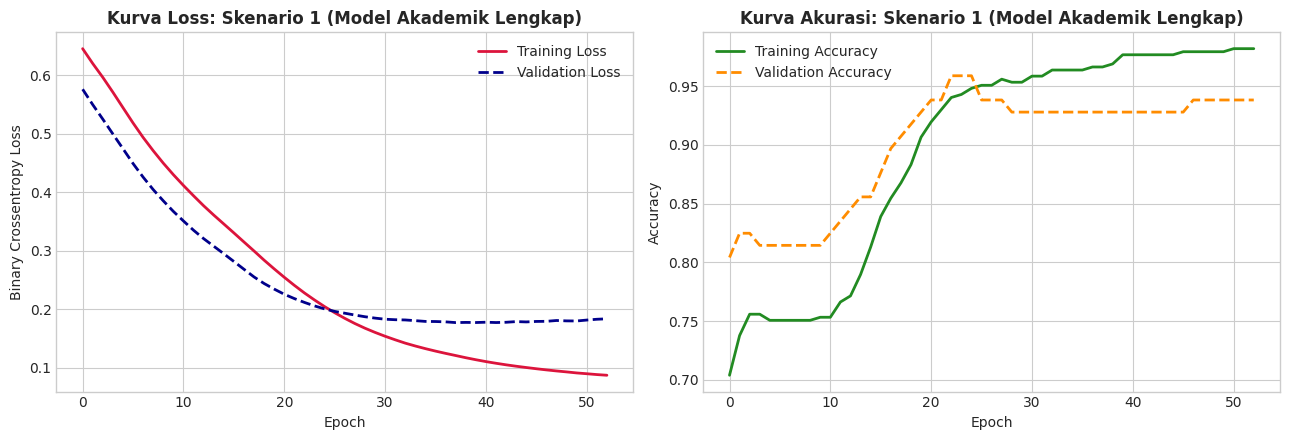

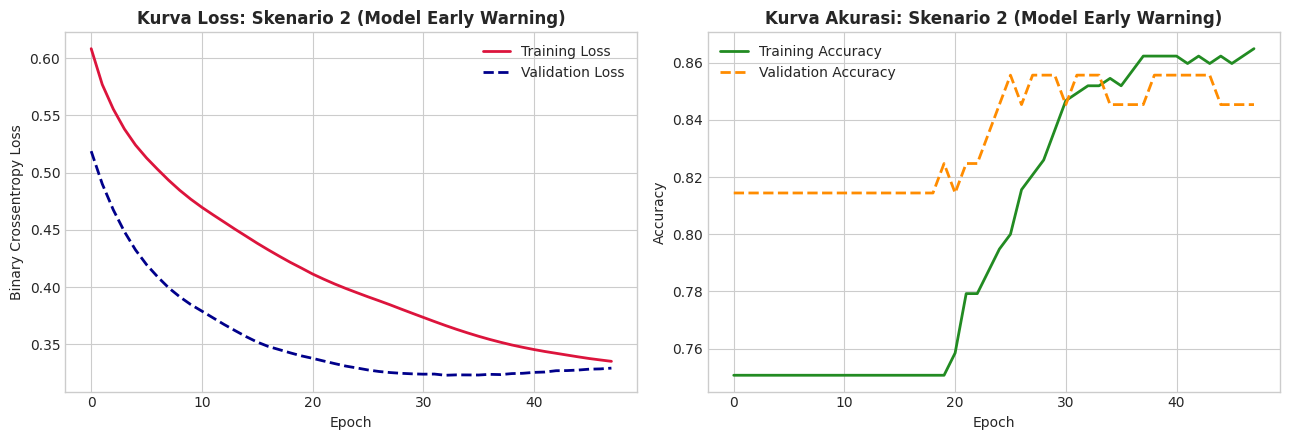

In [21]:
# Cell 21: Visualisasi Grafik Training Loss & Accuracy
def plot_training_history(history, title):
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4.5))
    
    # Grafik Loss
    ax1.plot(history.history['loss'], label='Training Loss', color='crimson', linewidth=2)
    ax1.plot(history.history['val_loss'], label='Validation Loss', color='darkblue', linestyle='--', linewidth=2)
    ax1.set_title(f'Kurva Loss: {title}', fontsize=12, fontweight='bold')
    ax1.set_xlabel('Epoch')
    ax1.set_ylabel('Binary Crossentropy Loss')
    ax1.legend()
    ax1.grid(True)
    
    # Grafik Akurasi
    ax2.plot(history.history['accuracy'], label='Training Accuracy', color='forestgreen', linewidth=2)
    ax2.plot(history.history['val_accuracy'], label='Validation Accuracy', color='darkorange', linestyle='--', linewidth=2)
    ax2.set_title(f'Kurva Akurasi: {title}', fontsize=12, fontweight='bold')
    ax2.set_xlabel('Epoch')
    ax2.set_ylabel('Accuracy')
    ax2.legend()
    ax2.grid(True)
    
    plt.tight_layout()
    plt.show()

# Visualisasikan kedua skenario
plot_training_history(history_s1, "Skenario 1 (Model Akademik Lengkap)")
plot_training_history(history_s2, "Skenario 2 (Model Early Warning)")


# TAHAP 9 & 10 — Evaluasi Model dan Analisis Hasil

### 9.1 Evaluasi pada Data Pengujian (*Testing Data*)
Pengujian dilakukan terhadap data uji ($20\%$) yang **sama sekali belum pernah dilihat oleh model** selama proses pelatihan.

Metrik yang dievaluasi mencakup:
- **Accuracy:** Proporsi prediksi benar secara keseluruhan.
- **Precision:** Ketepatan prediksi positif (seberapa banyak yang diprediksi tepat waktu yang benar-benar tepat waktu).
- **Recall:** Sensitivitas model (seberapa banyak mahasiswa yang sebenarnya tidak tepat waktu berhasil terdeteksi).
- **F1-Score:** Rata-rata harmonis antara precision dan recall (krusial untuk data dengan class imbalance).
- **Confusion Matrix:** Memvisualisasikan True Positive, False Positive, True Negative, dan False Negative.
- **ROC-AUC (Receiver Operating Characteristic - Area Under Curve):** Mengukur kemampuan model memisahkan kedua kelas pada berbagai ambang batas probabilitas.


In [22]:
# Cell 22: Fungsi Evaluasi Komprehensif
def evaluate_model_performance(model, X_test_proc, y_test, model_name="Model"):
    # 1. Prediksi Probabilitas & Kelas
    y_pred_prob = model.predict(X_test_proc).ravel()
    y_pred = (y_pred_prob >= 0.5).astype(int)
    
    # 2. Hitung Metrik Evaluasi
    acc = accuracy_score(y_test, y_pred)
    prec = precision_score(y_test, y_pred, zero_division=0)
    rec = recall_score(y_test, y_pred, zero_division=0)
    f1 = f1_score(y_test, y_pred, zero_division=0)
    roc_auc = roc_auc_score(y_test, y_pred_prob)
    
    print(f"=== LAPORAN EVALUASI: {model_name.upper()} ===")
    print(f"Akurasi (Accuracy)   : {acc:.4f} ({acc*100:.2f}%)")
    print(f"Presisi (Precision)  : {prec:.4f}")
    print(f"Recall (Sensitivitas): {rec:.4f}")
    print(f"F1-Score             : {f1:.4f}")
    print(f"ROC-AUC Score        : {roc_auc:.4f}")
    print("\nClassification Report:")
    print(classification_report(y_test, y_pred, target_names=['Tidak Tepat Waktu', 'Tepat Waktu'], digits=4))
    
    return {
        'model_name': model_name,
        'accuracy': acc,
        'precision': prec,
        'recall': rec,
        'f1': f1,
        'roc_auc': roc_auc,
        'y_pred_prob': y_pred_prob,
        'y_pred': y_pred
    }

# Evaluasi kedua model
eval_s1 = evaluate_model_performance(model_s1, X_test_proc_s1, y_test, "Skenario 1 (Semua Fitur)")
print("=" * 65)
eval_s2 = evaluate_model_performance(model_s2, X_test_proc_s2, y_test, "Skenario 2 (Tanpa IPK & Total SKS)")


4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 19ms/step
=== LAPORAN EVALUASI: SKENARIO 1 (SEMUA FITUR) ===
Akurasi (Accuracy)   : 0.9587 (95.87%)
Presisi (Precision)  : 0.9681
Recall (Sensitivitas): 0.9785
F1-Score             : 0.9733
ROC-AUC Score        : 0.9969

Classification Report:
                   precision    recall  f1-score   support

Tidak Tepat Waktu     0.9259    0.8929    0.9091        28
      Tepat Waktu     0.9681    0.9785    0.9733        93

         accuracy                         0.9587       121
        macro avg     0.9470    0.9357    0.9412       121
     weighted avg     0.9583    0.9587    0.9584       121

4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 15ms/step
=== LAPORAN EVALUASI: SKENARIO 2 (TANPA IPK & TOTAL SKS) ===
Akurasi (Accuracy)   : 0.7934 (79.34%)
Presisi (Precision)  : 0.8208
Recall (Sensitivitas): 0.9355
F1-Score             : 0.8744
ROC-AUC Score        : 0.8349

Classification Report:
                   precision    recall  f1-score   support

Tidak Tepat Waktu     0.6000 

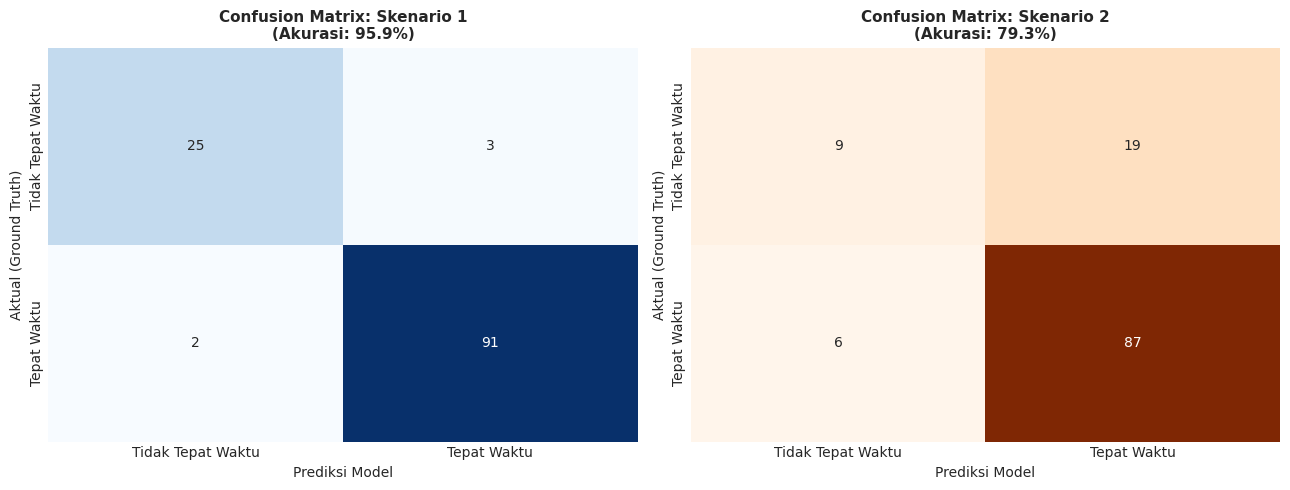

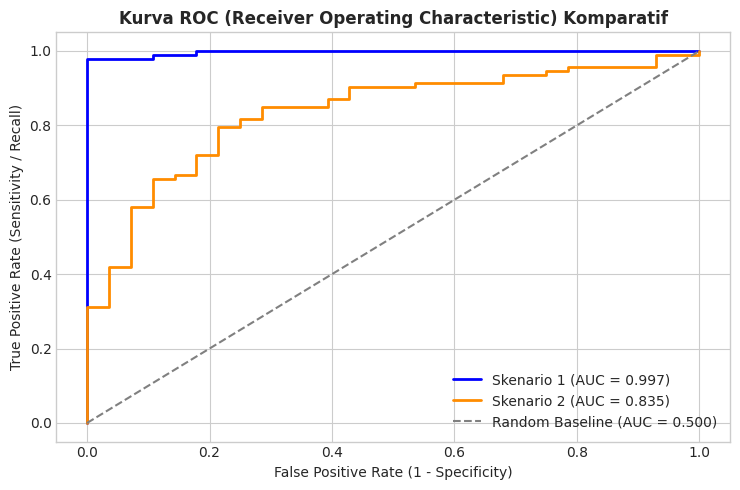

In [23]:
# Cell 23: Visualisasi Confusion Matrix & ROC Curves
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

# Confusion Matrix Skenario 1
cm_s1 = confusion_matrix(y_test, eval_s1['y_pred'])
sns.heatmap(cm_s1, annot=True, fmt='d', cmap='Blues', ax=axes[0],
            xticklabels=['Tidak Tepat Waktu', 'Tepat Waktu'],
            yticklabels=['Tidak Tepat Waktu', 'Tepat Waktu'], cbar=False)
axes[0].set_title(f"Confusion Matrix: Skenario 1\n(Akurasi: {eval_s1['accuracy']*100:.1f}%)", fontsize=11, fontweight='bold')
axes[0].set_xlabel('Prediksi Model')
axes[0].set_ylabel('Aktual (Ground Truth)')

# Confusion Matrix Skenario 2
cm_s2 = confusion_matrix(y_test, eval_s2['y_pred'])
sns.heatmap(cm_s2, annot=True, fmt='d', cmap='Oranges', ax=axes[1],
            xticklabels=['Tidak Tepat Waktu', 'Tepat Waktu'],
            yticklabels=['Tidak Tepat Waktu', 'Tepat Waktu'], cbar=False)
axes[1].set_title(f"Confusion Matrix: Skenario 2\n(Akurasi: {eval_s2['accuracy']*100:.1f}%)", fontsize=11, fontweight='bold')
axes[1].set_xlabel('Prediksi Model')
axes[1].set_ylabel('Aktual (Ground Truth)')

plt.tight_layout()
plt.show()

# Visualisasi Kurva ROC
plt.figure(figsize=(7.5, 5))
fpr_s1, tpr_s1, _ = roc_curve(y_test, eval_s1['y_pred_prob'])
fpr_s2, tpr_s2, _ = roc_curve(y_test, eval_s2['y_pred_prob'])

plt.plot(fpr_s1, tpr_s1, color='blue', lw=2, label=f"Skenario 1 (AUC = {eval_s1['roc_auc']:.3f})")
plt.plot(fpr_s2, tpr_s2, color='darkorange', lw=2, label=f"Skenario 2 (AUC = {eval_s2['roc_auc']:.3f})")
plt.plot([0, 1], [0, 1], color='gray', linestyle='--', label='Random Baseline (AUC = 0.500)')
plt.title('Kurva ROC (Receiver Operating Characteristic) Komparatif', fontsize=12, fontweight='bold')
plt.xlabel('False Positive Rate (1 - Specificity)')
plt.ylabel('True Positive Rate (Sensitivity / Recall)')
plt.legend(loc='lower right')
plt.grid(True)
plt.tight_layout()
plt.show()


In [24]:
# Cell 24: Tabel Ringkasan Komparasi Dua Skenario untuk Laporan BAB IV
df_comparison = pd.DataFrame([
    {
        'Skenario Eksperimen': 'Skenario 1 (Lengkap: Ada IPK & SKS)',
        'Akurasi': f"{eval_s1['accuracy']*100:.2f}%",
        'Presisi': f"{eval_s1['precision']:.4f}",
        'Recall': f"{eval_s1['recall']:.4f}",
        'F1-Score': f"{eval_s1['f1']:.4f}",
        'ROC-AUC': f"{eval_s1['roc_auc']:.4f}"
    },
    {
        'Skenario Eksperimen': 'Skenario 2 (Early Warning: Tanpa IPK & SKS)',
        'Akurasi': f"{eval_s2['accuracy']*100:.2f}%",
        'Presisi': f"{eval_s2['precision']:.4f}",
        'Recall': f"{eval_s2['recall']:.4f}",
        'F1-Score': f"{eval_s2['f1']:.4f}",
        'ROC-AUC': f"{eval_s2['roc_auc']:.4f}"
    }
])

print("=" * 75)
print("TABEL KOMPARASI PERFORMA MODEL UNTUK LAPORAN AKADEMIK (BAB IV)")
print("=" * 75)
display(df_comparison)


TABEL KOMPARASI PERFORMA MODEL UNTUK LAPORAN AKADEMIK (BAB IV)


,Skenario Eksperimen,Akurasi,Presisi,Recall,F1-Score,ROC-AUC
0,Skenario 1 (Lengkap: Ada IPK & SKS),95.87%,0.9681,0.9785,0.9733,0.9969
1,Skenario 2 (Early Warning: Tanpa IPK & SKS),79.34%,0.8208,0.9355,0.8744,0.8349


# TAHAP 11 — Penyimpanan & Export Model untuk Integrasi Web

### 11.1 Komponen yang Disimpan untuk Integrasi Web
Aplikasi web berbasis Flask/FastAPI/Streamlit membutuhkan seluruh artefak model agar dapat melakukan inferensi secara mandiri tanpa bergantung pada dataset mentah:
1. **Model ANN (`.keras`):** Struktur arsitektur dan bobot optimal hasil pelatihan Backpropagation.
2. **Preprocessing Pipeline (`.joblib`):** Objek `ColumnTransformer` yang sudah di-`fit` (berisi nilai median numerik, modus kategorikal, mean-std scaler, dan kategori OneHotEncoder).
3. **Metadata Skema (`.json`):** Berisi urutan fitur input, nama kolom, pemetaan label target (`0` dan `1`), serta catatan metrik pengujian.

### 11.2 Validasi Integritas Inferensi Mandiri
Notebook memuat kembali (*reload*) file yang disimpan dan menjalankan uji prediksi pada sampel data baru untuk menjamin konsistensi sebelum diekspor ke aplikasi web.


In [25]:
# Cell 25: Simpan Model, Pipeline, dan Metadata
import shutil

export_dir = 'model_web_deployment'
os.makedirs(export_dir, exist_ok=True)

# 1. Simpan Model ANN (Skenario 1 dipilih sebagai model utama karena performa optimal)
model_path = os.path.join(export_dir, 'model_ann_kelulusan.keras')
model_s1.save(model_path)
print(f"1. Model ANN berhasil disimpan: {model_path}")

# 2. Simpan Preprocessor Pipeline Scikit-Learn
pipeline_path = os.path.join(export_dir, 'pipeline_preprocessor.joblib')
joblib.dump(preprocessor_s1, pipeline_path)
print(f"2. Preprocessing Pipeline berhasil disimpan: {pipeline_path}")

# 3. Simpan Metadata Konfigurasi & Schema JSON
metadata = {
    'project_title': 'Prediksi Kelulusan Mahasiswa Menggunakan ANN Backpropagation Berbasis Web',
    'input_features': {
        'numeric_features': features_skenario1_num,
        'categorical_features': features_skenario1_cat,
        'feature_order': all_features_skenario1
    },
    'target_mapping': target_mapping,
    'reverse_target_mapping': reverse_target_mapping,
    'model_metrics': {
        'accuracy': round(eval_s1['accuracy'], 4),
        'precision': round(eval_s1['precision'], 4),
        'recall': round(eval_s1['recall'], 4),
        'f1_score': round(eval_s1['f1'], 4),
        'roc_auc': round(eval_s1['roc_auc'], 4)
    }
}

metadata_path = os.path.join(export_dir, 'metadata_model.json')
with open(metadata_path, 'w', encoding='utf-8') as f:
    json.dump(metadata, f, indent=4)
print(f"3. Metadata Skema JSON berhasil disimpan: {metadata_path}")


1. Model ANN berhasil disimpan: model_web_deployment\model_ann_kelulusan.keras
2. Preprocessing Pipeline berhasil disimpan: model_web_deployment\pipeline_preprocessor.joblib
3. Metadata Skema JSON berhasil disimpan: model_web_deployment\metadata_model.json


In [26]:
# Cell 26: Uji Verifikasi Prediksi Mandiri (Deployment Test)
print("=== UJI VERIFIKASI PEMUATAN MODEL & INFERENSI BARU ===")

# Muat kembali artefak
loaded_model = keras.models.load_model(model_path)
loaded_preprocessor = joblib.load(pipeline_path)

# Buat contoh data input simulasi dari antarmuka Web Form
dummy_input = pd.DataFrame([{
    'IPK': 3.45,
    'Kehadiran': 85.0,
    'Jumlah_Organisasi': 2,
    'Total_SKS': 135.0,
    'Penghasilan_Orang_Tua': 'Menengah',
    'Jam_Belajar': 20.0,
    'Kualitas_Internet': 'Baik'
}])

print("Contoh Data Masukan Web Form:")
display(dummy_input)

# Jalankan pipeline transformasi dan prediksi
dummy_proc = loaded_preprocessor.transform(dummy_input)
prob = float(loaded_model.predict(dummy_proc)[0][0])
pred_label = reverse_target_mapping[1 if prob >= 0.5 else 0]

print("\n--- HASIL INFERENSI SISTEM BERBASIS WEB ---")
print(f"Probabilitas Lulus Tepat Waktu : {prob * 100:.2f}%")
print(f"Prediksi Status Kelulusan      : {pred_label}")
print("Status: Verifikasi BERHASIL! Model siap dideploy ke Flask / FastAPI / Streamlit.")


=== UJI VERIFIKASI PEMUATAN MODEL & INFERENSI BARU ===
Contoh Data Masukan Web Form:


,IPK,Kehadiran,Jumlah_Organisasi,Total_SKS,Penghasilan_Orang_Tua,Jam_Belajar,Kualitas_Internet
0,3.45,85.0,2,135.0,Menengah,20.0,Baik


1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 65ms/step

--- HASIL INFERENSI SISTEM BERBASIS WEB ---
Probabilitas Lulus Tepat Waktu : 99.96%
Prediksi Status Kelulusan      : Tepat Waktu
Status: Verifikasi BERHASIL! Model siap dideploy ke Flask / FastAPI / Streamlit.


In [27]:
# Cell 27: Kompresi File Deployment & Download (Google Colab)
zip_filename = 'model_prediksi_kelulusan_web'
shutil.make_archive(zip_filename, 'zip', export_dir)
print(f"Paket deployment berhasil dikompresi: {zip_filename}.zip")

if is_colab:
    print("Mengunduh file zip secara otomatis ke komputer Anda...")
    files.download(f"{zip_filename}.zip")
else:
    print(f"File zip tersedia di: {os.path.abspath(zip_filename + '.zip')}")


Paket deployment berhasil dikompresi: model_prediksi_kelulusan_web.zip
File zip tersedia di: c:\MATERI KULIAH\SEMESTER 5\AI\UAS MK AI\model_prediksi_kelulusan_web.zip
